# 01 — Feature Inventory

**Purpose:** establish integrity, coverage, missingness, and the basic statistical profile of the model-facing feature dataset before regime modeling.

This notebook:
- opens `research.duckdb` in **read-only** mode;
- treats `time_series_feature_state` as the primary model-facing dataset;
- inspects the long-form option and L2-distribution tables when available;
- checks duplicates, temporal continuity, readiness coverage, missingness, infinities, constants, and extreme values;
- does **not** standardize, winsorize, impute, or mutate data.

> Research rule: notebooks discover; production Python modules implement accepted transformations.

## 1. Environment and read-only database connection

In [1]:
from pathlib import Path
import os
import math
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)

load_dotenv()

data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError("DERIBIT_DATA_ROOT is not defined in the environment/.env file.")

DATA_ROOT = Path(data_root_env).expanduser().resolve()
DB_PATH = DATA_ROOT / "database" / "research.duckdb"

if not DB_PATH.exists():
    raise FileNotFoundError(f"Research database not found: {DB_PATH}")

con = duckdb.connect(str(DB_PATH), read_only=True)

print(f"Research DB: {DB_PATH}")
print("Connection mode: read-only")

Research DB: D:\MarketData\Deribit\database\research.duckdb
Connection mode: read-only


## 2. Feature-layer relation inventory

In [2]:
relations = con.execute(
    """
    SELECT table_schema, table_name, table_type
    FROM information_schema.tables
    WHERE table_schema NOT IN ('information_schema', 'pg_catalog')
    ORDER BY table_schema, table_name
    """
).df()

feature_relations = [
    "time_series_feature_state",
    "option_surface_feature_state",
    "primary_option_surface_feature_state",
    "l2_instability_distribution_state",
]

display(relations[relations["table_name"].isin(feature_relations)].reset_index(drop=True))

missing_relations = [name for name in feature_relations if name not in set(relations["table_name"])]
print("Missing relations:" if missing_relations else "All expected feature-layer relations are present.", missing_relations)

,table_schema,table_name,table_type
0,main,l2_instability_distribution_state,BASE TABLE
1,main,option_surface_feature_state,BASE TABLE
2,main,primary_option_surface_feature_state,BASE TABLE
3,main,time_series_feature_state,BASE TABLE


All expected feature-layer relations are present. []


## 3. Load the model-facing state table

Expected grain: **one row = one underlying × one 5-minute state**.

In [3]:
features = con.execute(
    """
    SELECT *
    FROM time_series_feature_state
    ORDER BY state_time, underlying
    """
).df()

print(f"Rows:    {len(features):,}")
print(f"Columns: {features.shape[1]:,}")
display(features.head())

Rows:    32,256
Columns: 152


,state_id,state_time,underlying,session_id,expiry_date,session_start,session_end,minutes_to_expiry,is_opening_state,minutes_since_session_start,session_progress_fraction,collection_complete,price_features_ready,state_research_ready,l2_boundary_ready,l2_intrawindow_ready,futures_instrument_name,futures_tradable_mid_price,futures_mark_price,futures_index_price,futures_underlying_price,market_reference_price,market_reference_source,market_reference_is_tradable,futures_ticker_age_ms,futures_spread_bps,perpetual_mid_vs_index_bps,perpetual_mark_vs_index_bps,microprice_vs_mid_bps,return_input_eligible,index_return_input_eligible,open,high,low,close,vwap,volume_usd,buy_volume_usd,sell_volume_usd,trade_count,open_interest,book_stats_coverage_ms,book_stats_complete,book_update_count,book_twa_spread,book_twa_obi_5,book_twa_obi_10,book_twa_obi_20,book_twa_bid_depth_20,book_twa_ask_depth_20,book_twa_microprice,book_min_obi_20,book_max_obi_20,book_twa_abs_obi_20,book_obi_20_std,book_obi_20_path_roughness_per_min,book_obi_20_range,book_obi_20_coherence_noise,book_obi_20_transition_count,book_obi_20_raw_zero_cross_count,book_obi_20_raw_zero_cross_rate,book_obi_20_reversal_strength_mean,book_obi_20_reversal_strength_max,return_5m,return_15m,return_30m,return_1h,perp_mid_return_5m,return_source,log1p_volume_usd,signed_volume_usd,trade_flow_imbalance,buy_volume_share,average_trade_size_usd,intrabar_range_bps,close_vs_vwap_bps,open_interest_change_5m,open_interest_return_5m,book_twa_spread_bps,book_twa_microprice_vs_reference_bps,book_twa_obi_20_change_5m,l2_instability_scalar_available,l2_coherence_available,rv_30m_return_count,rv_1h_return_count,rv_4h_return_count,realized_vol_30m,realized_vol_30m_annualized,realized_vol_1h,realized_vol_1h_annualized,realized_vol_4h,realized_vol_4h_annualized,realized_vol_30m_ready,realized_vol_1h_ready,realized_vol_4h_ready,microstructure_core_ready,l2_instability_features_ready,primary_option_family_id,primary_option_instrument_type,primary_option_settlement_currency,primary_option_api_currency,option_family_selection_reason,option_forward_price,option_iv_atm_forward,option_skew_025,option_skew_050,option_curvature_025,option_curvature_050,option_local_skew_slope_025,option_local_skew_slope_050,core_smile_quality_tier,core_smile_tight,core_smile_usable,wing_050_usable,full_grid_usable,core_max_interpolation_span,wing_050_max_interpolation_span,full_grid_max_interpolation_span,option_base_eligible_rows,option_two_sided_eligible_rows,option_median_two_sided_spread_bps,option_p90_two_sided_spread_bps,atm_iv_change_5m,atm_iv_change_15m,atm_iv_change_1h,skew_025_change_5m,skew_025_change_15m,skew_025_change_1h,curvature_025_change_5m,curvature_025_change_15m,curvature_025_change_1h,skew_050_change_5m,core_surface_change_5m_ready,iv_put_25d,iv_call_25d,rr_25d,bf_25d,iv_put_10d,iv_call_10d,rr_10d,bf_10d,delta_25d_smile_available,full_delta_smile_available,max_delta_interpolation_span,median_delta_interpolation_span,rr_25d_change_5m,bf_25d_change_5m,delta_25d_change_5m_ready,structural_level_features_ready,structural_dynamic_features_ready,microstructure_features_ready,instability_features_ready
0,AVAX|2026-09-19T08:00:00Z,2026-09-19 10:00:00+02:00,AVAX,expiry=2026-09-20,2026-09-20,2026-09-19 10:00:00+02:00,2026-09-20 10:00:00+02:00,1440,True,0,0.0,False,False,False,False,False,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,deribit_index,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,<NA>,False,False,False,False
1,BTC|2026-09-19T08:00:00Z,2026-09-19 10:00:00+02:00,BTC,expiry=2

## 4. Dataset identity and coverage

In [4]:
overview = pd.Series({
    "rows": len(features),
    "columns": features.shape[1],
    "unique_state_ids": features["state_id"].nunique(dropna=True),
    "underlyings": features["underlying"].nunique(dropna=True),
    "first_state": features["state_time"].min(),
    "last_state": features["state_time"].max(),
    "first_expiry": features["expiry_date"].min(),
    "last_expiry": features["expiry_date"].max(),
}, name="value").to_frame()

display(overview)

,value
rows,32256
columns,152
unique_state_ids,32256
underlyings,7
first_state,2026-09-19 10:00:00+02:00
last_state,2026-10-05 09:55:00+02:00
first_expiry,2026-09-20 00:00:00
last_expiry,2026-10-05 00:00:00


In [5]:
asset_counts = (
    features.groupby("underlying", dropna=False)
    .agg(
        rows=("state_id", "size"),
        unique_states=("state_id", "nunique"),
        first_state=("state_time", "min"),
        last_state=("state_time", "max"),
        research_ready=("state_research_ready", lambda s: int(s.fillna(False).sum())),
    )
    .reset_index()
)
asset_counts["research_ready_pct"] = 100.0 * asset_counts["research_ready"] / asset_counts["rows"]
display(asset_counts)

,underlying,rows,unique_states,first_state,last_state,research_ready,research_ready_pct
0,AVAX,4608,4608,2026-09-19 10:00:00+02:00,2026-10-05 09:55:00+02:00,3934,85.373264
1,BTC,4608,4608,2026-09-19 10:00:00+02:00,2026-10-05 09:55:00+02:00,3934,85.373264
2,ETH,4608,4608,2026-09-19 10:00:00+02:00,2026-10-05 09:55:00+02:00,3934,85.373264
3,HYPE,4608,4608,2026-09-19 10:00:00+02:00,2026-10-05 09:55:00+02:00,3934,85.373264
4,SOL,4608,4608,2026-09-19 10:00:00+02:00,2026-10-05 09:55:00+02:00,3934,85.373264
5,TRX,4608,4608,2026-09-19 10:00:00+02:00,2026-10-05 09:55:00+02:00,3934,85.373264
6,XRP,4608,4608,2026-09-19 10:00:00+02:00,2026-10-05 09:55:00+02:00,3934,85.373264


In [6]:
expiry_counts = (
    features.groupby("expiry_date", dropna=False)
    .agg(
        rows=("state_id", "size"),
        underlyings=("underlying", "nunique"),
        research_ready=("state_research_ready", lambda s: int(s.fillna(False).sum())),
        structural_level=("structural_level_features_ready", lambda s: int(s.fillna(False).sum())),
        structural_dynamic=("structural_dynamic_features_ready", lambda s: int(s.fillna(False).sum())),
        microstructure=("microstructure_features_ready", lambda s: int(s.fillna(False).sum())),
        instability=("instability_features_ready", lambda s: int(s.fillna(False).sum())),
    )
    .reset_index()
)

for col in ["research_ready", "structural_level", "structural_dynamic", "microstructure", "instability"]:
    expiry_counts[f"{col}_pct"] = 100.0 * expiry_counts[col] / expiry_counts["rows"]

display(expiry_counts)

,expiry_date,rows,underlyings,research_ready,structural_level,structural_dynamic,microstructure,instability,research_ready_pct,structural_level_pct,structural_dynamic_pct,microstructure_pct,instability_pct
0,2026-09-20,2016,7,0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000
1,2026-09-21,2016,7,0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000
2,2026-09-22,2016,7,1778,1641,1471,0,0,88.194444,81.398810,72.966270,0.000000,0.000000
3,2026-09-23,2016,7,1967,1931,1646,1890,0,97.569444,95.783730,81.646825,93.750000,0.000000
4,2026-09-24,2016,7,1988,1959,1692,1995,0,98.611111,97.172619,83.928571,98.958333,0.000000
5,2026-09-25,2016,7,1974,1933,1550,1981,0,97.916667,95.882937,76.884921,98.263889,0.000000
6,2026-09-26,2016,7,1960,1896,1335,1967,0,97.222222,94.047619,66.220238,97.569444,0.000000
7,2026-09-27,2016,7,2009,1992,1913,2016,0,99.652778,98.809524,94.890873,100.000000,0.000000
8,2026-09-28,2016,7,2009,1999,1938,2016,0,99.652778,99.156746,96.130952,100.000000,0.000000
9,2026-09-29,2016,7,1953,1910,1543,1960,0,96.875000,94.742063,76.537698,97.222222,0.000000


## 5. Uniqueness checks

In [7]:
duplicate_state_ids = int(features["state_id"].duplicated().sum())
duplicate_underlying_times = int(features.duplicated(subset=["underlying", "state_time"]).sum())

print(f"Duplicate state_id rows:               {duplicate_state_ids:,}")
print(f"Duplicate underlying × timestamp rows: {duplicate_underlying_times:,}")

assert duplicate_state_ids == 0
assert duplicate_underlying_times == 0

Duplicate state_id rows:               0
Duplicate underlying × timestamp rows: 0


## 6. Column inventory and dtypes

In [8]:
dtype_inventory = pd.DataFrame({
    "column": features.columns,
    "dtype": [str(features[c].dtype) for c in features.columns],
    "non_null": [int(features[c].notna().sum()) for c in features.columns],
    "null": [int(features[c].isna().sum()) for c in features.columns],
    "unique": [int(features[c].nunique(dropna=True)) for c in features.columns],
})
dtype_inventory["missing_pct"] = 100.0 * dtype_inventory["null"] / len(features)
display(dtype_inventory)

,column,dtype,non_null,null,unique,missing_pct
0,state_id,str,32256,0,32256,0.000000
1,state_time,"datetime64[us, Europe/Madrid]",32256,0,4608,0.000000
2,underlying,str,32256,0,7,0.000000
3,session_id,str,32256,0,16,0.000000
4,expiry_date,datetime64[us],32256,0,16,0.000000
5,session_start,"datetime64[us, Europe/Madrid]",32256,0,16,0.000000
6,session_end,"datetime64[us, Europe/Madrid]",32256,0,16,0.000000
7,minutes_to_expiry,int64,32256,0,288,0.000000
8,is_opening_state,bool,32256,0,2,0.000000
9,minutes_since_session_start,int64,32256,0,288,0.000000


## 7. Missingness profile

Missingness is not automatically a defect: it can encode pre-collector history, readiness failures, sparse option wings/delta points, rolling-window warm-up, or intentional non-backfill of new L2 statistics.

In [9]:
missingness = pd.DataFrame({
    "column": features.columns,
    "missing": [int(features[c].isna().sum()) for c in features.columns],
    "available": [int(features[c].notna().sum()) for c in features.columns],
})
missingness["missing_pct"] = 100.0 * missingness["missing"] / len(features)
missingness = missingness.sort_values(["missing_pct", "column"], ascending=[False, True]).reset_index(drop=True)
display(missingness)

,column,missing,available,missing_pct
0,futures_underlying_price,32256,0,100.000000
1,book_obi_20_reversal_strength_max,24741,7515,76.702009
2,book_obi_20_reversal_strength_mean,24741,7515,76.702009
3,book_obi_20_coherence_noise,24430,7826,75.737847
4,book_obi_20_path_roughness_per_min,24430,7826,75.737847
5,book_obi_20_range,24430,7826,75.737847
6,book_obi_20_raw_zero_cross_count,24430,7826,75.737847
7,book_obi_20_raw_zero_cross_rate,24430,7826,75.737847
8,book_obi_20_std,24430,7826,75.737847
9,book_obi_20_transition_count,24430,7826,75.737847


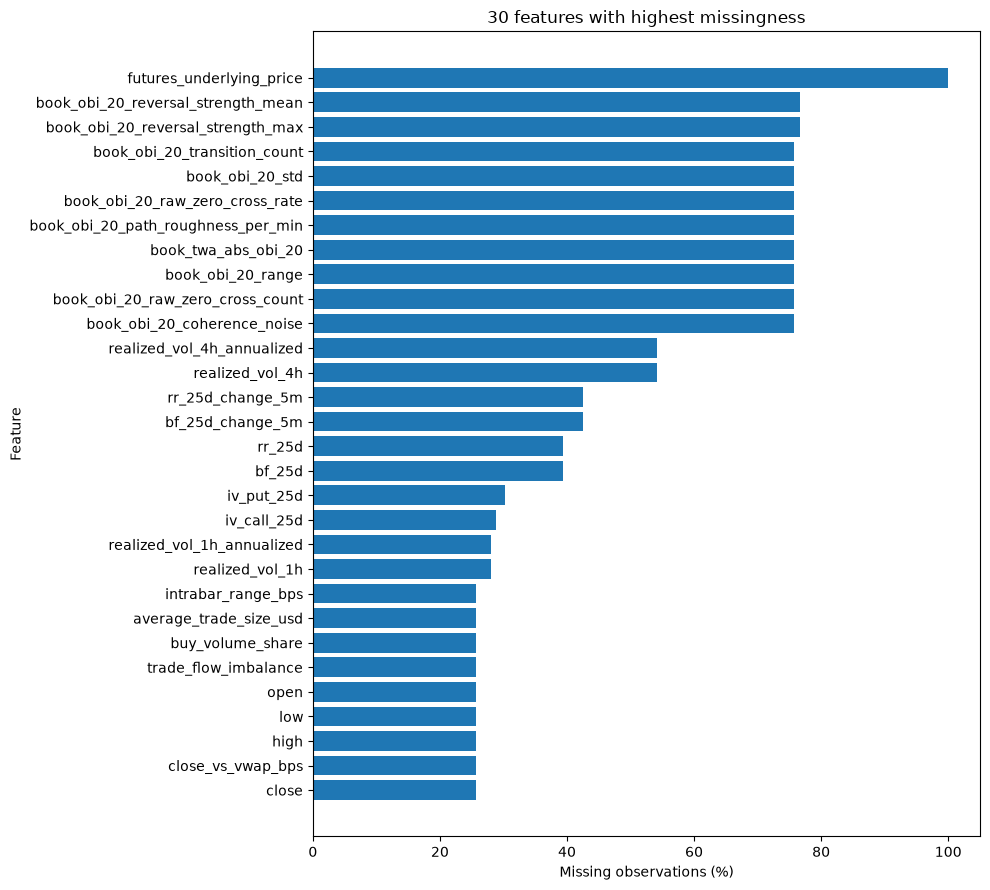

In [10]:
top_missing = missingness.head(30).sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top_missing["column"], top_missing["missing_pct"])
ax.set_xlabel("Missing observations (%)")
ax.set_ylabel("Feature")
ax.set_title("30 features with highest missingness")
plt.tight_layout()
plt.show()

## 8. Readiness coverage

In [11]:
readiness_columns = [c for c in [
    "collection_complete",
    "price_features_ready",
    "state_research_ready",
    "l2_boundary_ready",
    "l2_intrawindow_ready",
    "realized_vol_30m_ready",
    "realized_vol_1h_ready",
    "realized_vol_4h_ready",
    "core_smile_usable",
    "core_surface_change_5m_ready",
    "delta_25d_smile_available",
    "delta_25d_change_5m_ready",
    "structural_level_features_ready",
    "structural_dynamic_features_ready",
    "microstructure_features_ready",
    "instability_features_ready",
] if c in features.columns]

readiness_summary = []
for col in readiness_columns:
    true_count = int(features[col].fillna(False).sum())
    readiness_summary.append({
        "flag": col,
        "true": true_count,
        "false_or_null": len(features) - true_count,
        "coverage_pct": 100.0 * true_count / len(features),
    })

readiness_summary = pd.DataFrame(readiness_summary).sort_values("coverage_pct", ascending=False).reset_index(drop=True)
display(readiness_summary)

,flag,true,false_or_null,coverage_pct
0,collection_complete,27986,4270,86.762153
1,price_features_ready,27608,4648,85.590278
2,state_research_ready,27538,4718,85.373264
3,core_smile_usable,27419,4837,85.004340
4,core_surface_change_5m_ready,26953,5303,83.559648
5,structural_level_features_ready,26917,5339,83.448041
6,l2_boundary_ready,26096,6160,80.902778
7,l2_intrawindow_ready,25739,6517,79.796007
8,microstructure_features_ready,25739,6517,79.796007
9,realized_vol_30m_ready,25159,7097,77.997892


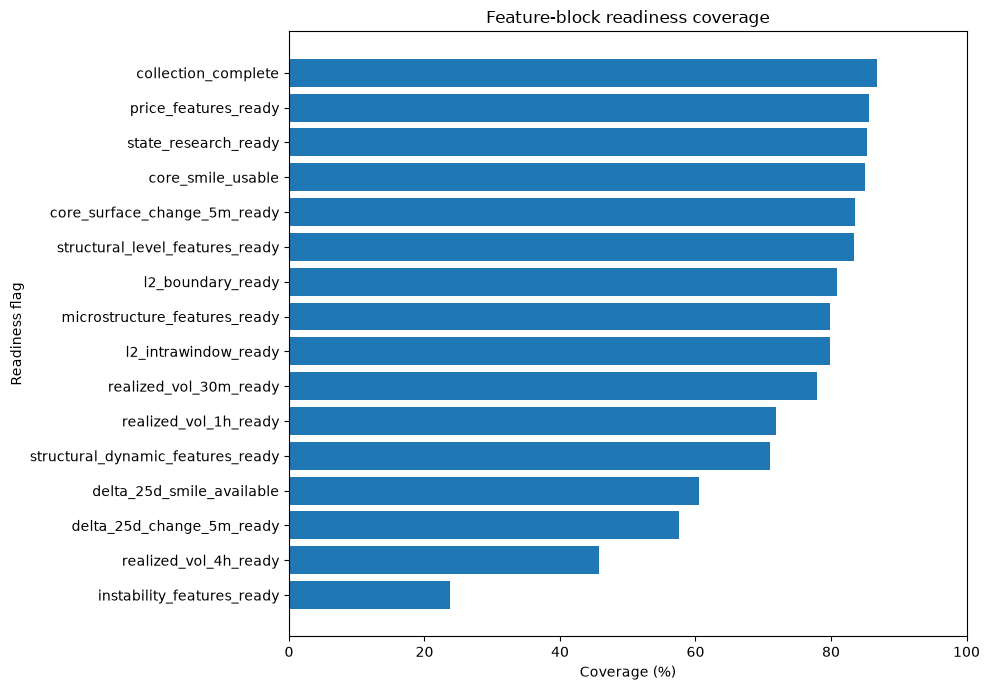

In [12]:
fig, ax = plt.subplots(figsize=(10, 7))
ordered_flags = readiness_summary.sort_values("coverage_pct")
ax.barh(ordered_flags["flag"], ordered_flags["coverage_pct"])
ax.set_xlim(0, 100)
ax.set_xlabel("Coverage (%)")
ax.set_ylabel("Readiness flag")
ax.set_title("Feature-block readiness coverage")
plt.tight_layout()
plt.show()

## 9. Numeric features, infinities, and quantiles

In [13]:
numeric_columns = features.select_dtypes(include=[np.number]).columns.tolist()
boolean_columns = [c for c in features.columns if str(features[c].dtype) in {"bool", "boolean"}]
numeric_feature_columns = [c for c in numeric_columns if c not in boolean_columns]

print(f"Numeric columns:         {len(numeric_columns)}")
print(f"Numeric feature columns: {len(numeric_feature_columns)}")
print(f"Boolean columns:         {len(boolean_columns)}")

Numeric columns:         107
Numeric feature columns: 107
Boolean columns:         29


In [14]:
infinity_rows = []
for col in numeric_feature_columns:
    arr = pd.to_numeric(features[col], errors="coerce").to_numpy(dtype=float, na_value=np.nan)
    pos_inf = int(np.isposinf(arr).sum())
    neg_inf = int(np.isneginf(arr).sum())
    if pos_inf or neg_inf:
        infinity_rows.append({"column": col, "positive_inf": pos_inf, "negative_inf": neg_inf})

infinity_summary = pd.DataFrame(infinity_rows, columns=["column", "positive_inf", "negative_inf"])
print(f"Columns containing ±inf: {len(infinity_summary)}")
display(infinity_summary)

Columns containing ±inf: 0


,column,positive_inf,negative_inf


In [15]:
quantiles = [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
summary_rows = []

for col in numeric_feature_columns:
    s = pd.to_numeric(features[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    row = {
        "column": col,
        "n": len(s),
        "missing_pct": 100.0 * (len(features) - len(s)) / len(features),
    }
    if len(s):
        row.update({"mean": s.mean(), "std": s.std(), "min": s.min(), "max": s.max()})
        for q, value in s.quantile(quantiles).items():
            row[f"q_{q:g}"] = value
    summary_rows.append(row)

numeric_summary = pd.DataFrame(summary_rows)
display(numeric_summary)

,column,n,missing_pct,mean,std,min,max,q_0.001,q_0.01,q_0.05,q_0.25,q_0.5,q_0.75,q_0.95,q_0.99,q_0.999
0,minutes_to_expiry,32256,0.000000,7.225000e+02,4.156961e+02,5.000000e+00,1.440000e+03,5.000000e+00,15.000000,75.000000,363.750000,722.500000,1.081250e+03,1.370000e+03,1.430000e+03,1.440000e+03
1,minutes_since_session_start,32256,0.000000,7.175000e+02,4.156961e+02,0.000000e+00,1.435000e+03,0.000000e+00,10.000000,70.000000,358.750000,717.500000,1.076250e+03,1.365000e+03,1.425000e+03,1.435000e+03
2,session_progress_fraction,32256,0.000000,4.982639e-01,2.886779e-01,0.000000e+00,9.965278e-01,0.000000e+00,0.006944,0.048611,0.249132,0.498264,7.473958e-01,9.479167e-01,9.895833e-01,9.965278e-01
3,futures_tradable_mid_price,27972,13.281250,1.250497e+04,2.945518e+04,3.317900e-01,8.729200e+04,3.325599e-01,0.333710,0.335300,1.535150,90.811000,2.681008e+03,8.478804e+04,8.640670e+04,8.687452e+04
4,futures_mark_price,27972,13.281250,1.250507e+04,2.945542e+04,3.317270e-01,8.730491e+04,3.325439e-01,0.333722,0.335315,1.535100,90.814000,2.681010e+03,8.478817e+04,8.640662e+04,8.687879e+04
5,futures_index_price,27972,13.281250,1.250186e+04,2.944784e+04,3.322420e-01,8.727324e+04,3.327409e-01,0.333737,0.335385,1.534600,90.788000,2.680620e+03,8.477008e+04,8.638022e+04,8.683853e+04
6,futures_underlying_price,0,100.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,market_reference_price,27972,13.281250,1.250497e+04,2.945518e+04,3.317900e-01,8.729200e+04,3.325599e-01,0.333710,0.335300,1.535150,90.811000,2.681008e+03,8.478804e+04,8.640670e+04,8.687452e+04
8,futures_ticker_age_ms,27972,13.281250,1.362568e+03,3.249758e+03,6.000000e+01,6.244000e+04,7.700000e+01,108.000000,169.000000,325.000000,510.000000,1.022000e+03,5.136450e+03,1.633695e+04,4.168782e+04
9,futures_spread_bps,27972,13.281250,2.530750e+00,1.965534e+01,1.146448e-02,2.139638e+03,1.151891e-02,0.011578,0.011806,0.037381,0.998206,3.134179e+00,5.871675e+00,7.852134e+00,3.289275e+02


## 10. Constant and near-constant features

`dominant_share` is the fraction of non-null observations occupied by the most frequent value.

In [16]:
constant_rows = []
for col in features.columns:
    s = features[col].dropna()
    if len(s) == 0:
        constant_rows.append({"column": col, "non_null": 0, "unique": 0, "dominant_share": np.nan, "status": "all_missing"})
        continue
    counts = s.value_counts(dropna=True)
    unique = int(len(counts))
    dominant_share = float(counts.iloc[0] / len(s))
    status = None
    if unique == 1:
        status = "constant"
    elif dominant_share >= 0.995:
        status = "near_constant"
    if status:
        constant_rows.append({"column": col, "non_null": len(s), "unique": unique, "dominant_share": dominant_share, "status": status})

constant_summary = pd.DataFrame(constant_rows)
if not constant_summary.empty:
    constant_summary = constant_summary.sort_values(["status", "dominant_share"], ascending=[True, False], na_position="last").reset_index(drop=True)
display(constant_summary)

,column,non_null,unique,dominant_share,status
0,futures_underlying_price,0,0,NaN,all_missing
1,market_reference_source,27972,1,1.000000,constant
2,market_reference_is_tradable,27972,1,1.000000,constant
3,return_source,32256,1,1.000000,constant
4,primary_option_instrument_type,29750,1,1.000000,constant
5,primary_option_settlement_currency,29750,1,1.000000,constant
6,primary_option_api_currency,29750,1,1.000000,constant
7,option_family_selection_reason,29750,1,1.000000,constant
8,is_opening_state,32256,2,0.996528,near_constant


## 11. Temporal continuity

The canonical grid should preserve expected 5-minute timestamps. This verifies that the time index itself has not developed irregular gaps.

In [17]:
ordered = features[["underlying", "state_time", "state_id"]].sort_values(["underlying", "state_time"]).copy()
ordered["delta_minutes"] = ordered.groupby("underlying")["state_time"].diff().dt.total_seconds().div(60.0)
irregular = ordered[ordered["delta_minutes"].notna() & (ordered["delta_minutes"] != 5.0)]

gap_summary = (
    irregular.groupby("underlying")
    .agg(
        irregular_intervals=("delta_minutes", "size"),
        min_gap_minutes=("delta_minutes", "min"),
        max_gap_minutes=("delta_minutes", "max"),
    )
    .reset_index()
)

print(f"Irregular asset-level timestamp intervals: {len(irregular):,}")
display(gap_summary)

Irregular asset-level timestamp intervals: 0


,underlying,irregular_intervals,min_gap_minutes,max_gap_minutes


## 12. Feature availability by asset

In [18]:
candidate_features = [c for c in [
    "return_5m",
    "realized_vol_1h",
    "option_iv_atm_forward",
    "option_skew_025",
    "option_curvature_025",
    "atm_iv_change_5m",
    "skew_025_change_5m",
    "curvature_025_change_5m",
    "rr_25d",
    "bf_25d",
    "book_twa_obi_20",
    "book_obi_20_std",
    "book_obi_20_path_roughness_per_min",
    "book_obi_20_coherence_noise",
] if c in features.columns]

availability_by_asset = []
for asset, group in features.groupby("underlying"):
    row = {"underlying": asset, "rows": len(group)}
    for col in candidate_features:
        row[f"{col}_pct"] = 100.0 * group[col].notna().mean()
    availability_by_asset.append(row)

availability_by_asset = pd.DataFrame(availability_by_asset).sort_values("underlying")
display(availability_by_asset)

,underlying,rows,return_5m_pct,realized_vol_1h_pct,option_iv_atm_forward_pct,option_skew_025_pct,option_curvature_025_pct,atm_iv_change_5m_pct,skew_025_change_5m_pct,curvature_025_change_5m_pct,rr_25d_pct,bf_25d_pct,book_twa_obi_20_pct,book_obi_20_std_pct,book_obi_20_path_roughness_per_min_pct,book_obi_20_coherence_noise_pct
0,AVAX,4608,84.353299,73.524306,85.373264,85.373264,85.373264,83.940972,83.940972,83.940972,76.692708,76.692708,80.924479,24.262153,24.262153,24.262153
1,BTC,4608,84.483507,74.045139,85.373264,85.373264,85.373264,83.940972,83.940972,83.940972,53.276910,53.276910,80.924479,24.262153,24.262153,24.262153
2,ETH,4608,84.483507,74.045139,85.373264,85.373264,85.373264,83.940972,83.940972,83.940972,57.074653,57.074653,80.924479,24.262153,24.262153,24.262153
3,HYPE,4608,84.483507,74.045139,85.373264,85.373264,85.373264,83.940972,83.940972,83.940972,66.970486,66.970486,80.924479,24.262153,24.262153,24.262153
4,SOL,4608,84.483507,74.045139,85.373264,85.373264,85.373264,83.940972,83.940972,83.940972,73.155382,73.155382,80.924479,24.262153,24.262153,24.262153
5,TRX,4608,81.575521,60.286458,85.373264,85.373264,85.373264,83.940972,83.940972,83.940972,30.685764,30.685764,80.924479,24.262153,24.262153,24.262153
6,XRP,4608,84.353299,73.198785,85.047743,82.790799,82.790799,81.271701,81.271701,81.271701,66.124132,66.124132,80.924479,24.262153,24.262153,24.262153


## 13. Core distribution snapshot

This is only a first look. Dedicated notebooks will examine transformations, ECDFs, tails, autocorrelation, conditioning, and cross-feature relationships.

In [19]:
distribution_features = [c for c in [
    "return_5m",
    "realized_vol_1h_annualized",
    "log1p_volume_usd",
    "trade_flow_imbalance",
    "futures_spread_bps",
    "perpetual_mid_vs_index_bps",
    "book_twa_obi_20",
    "option_iv_atm_forward",
    "option_skew_025",
    "option_curvature_025",
    "atm_iv_change_5m",
] if c in features.columns]

distribution_snapshot = numeric_summary[numeric_summary["column"].isin(distribution_features)].set_index("column").reindex(distribution_features).reset_index()
display(distribution_snapshot)

,column,n,missing_pct,mean,std,min,max,q_0.001,q_0.01,q_0.05,q_0.25,q_0.5,q_0.75,q_0.95,q_0.99,q_0.999
0,return_5m,27105,15.969122,0.000002,0.001877,-0.023029,0.021486,-0.011199,-0.005453,-0.002784,-0.000711,0.000000,0.000716,0.002853,0.005433,0.011465
1,realized_vol_1h_annualized,23187,28.115699,0.492816,0.356084,0.023748,2.669111,0.030434,0.057039,0.097232,0.228984,0.403362,0.669997,1.143507,1.718928,2.528369
2,log1p_volume_usd,27993,13.216146,8.488241,4.246945,0.000000,18.381071,0.000000,0.000000,0.000000,6.848776,9.551428,11.364543,13.806505,15.255842,16.204996
3,trade_flow_imbalance,23961,25.716146,-0.020292,0.656986,-1.000000,1.000000,-1.000000,-1.000000,-1.000000,-0.570132,-0.005646,0.487259,1.000000,1.000000,1.000000
4,futures_spread_bps,27972,13.281250,2.530750,19.655341,0.011464,2139.637859,0.011519,0.011578,0.011806,0.037381,0.998206,3.134179,5.871675,7.852134,328.927522
5,perpetual_mid_vs_index_bps,27972,13.281250,2.719275,8.630900,-87.965324,1012.713340,-26.309839,-5.887362,-2.322752,1.264026,2.628891,3.983415,7.354150,10.414548,45.280317
6,book_twa_obi_20,26103,19.075521,-0.010237,0.157628,-0.807421,0.714406,-0.616898,-0.470837,-0.303300,-0.077179,0.001373,0.069485,0.217688,0.432675,0.632836
7,option_iv_atm_forward,27523,14.673239,47.777620,23.346489,8.654510,457.556512,10.756624,13.135651,17.748469,26.175829,44.524728,64.988142,88.710157,102.791686,123.146203
8,option_skew_025,27419,14.995660,3.053471,9.419462,-56.083210,379.486618,-48.434144,-16.870000,-8.649549,-0.984698,2.867418,6.748553,15.221104,24.694249,66.479585
9,option_curvature_025,27419,14.995660,9.042142,8.173885,-416.786227,198.451851,-14.181589,-1.406244,0.903798,3.745377,7.701573,13.017349,21.784507,32.260661,53.312580


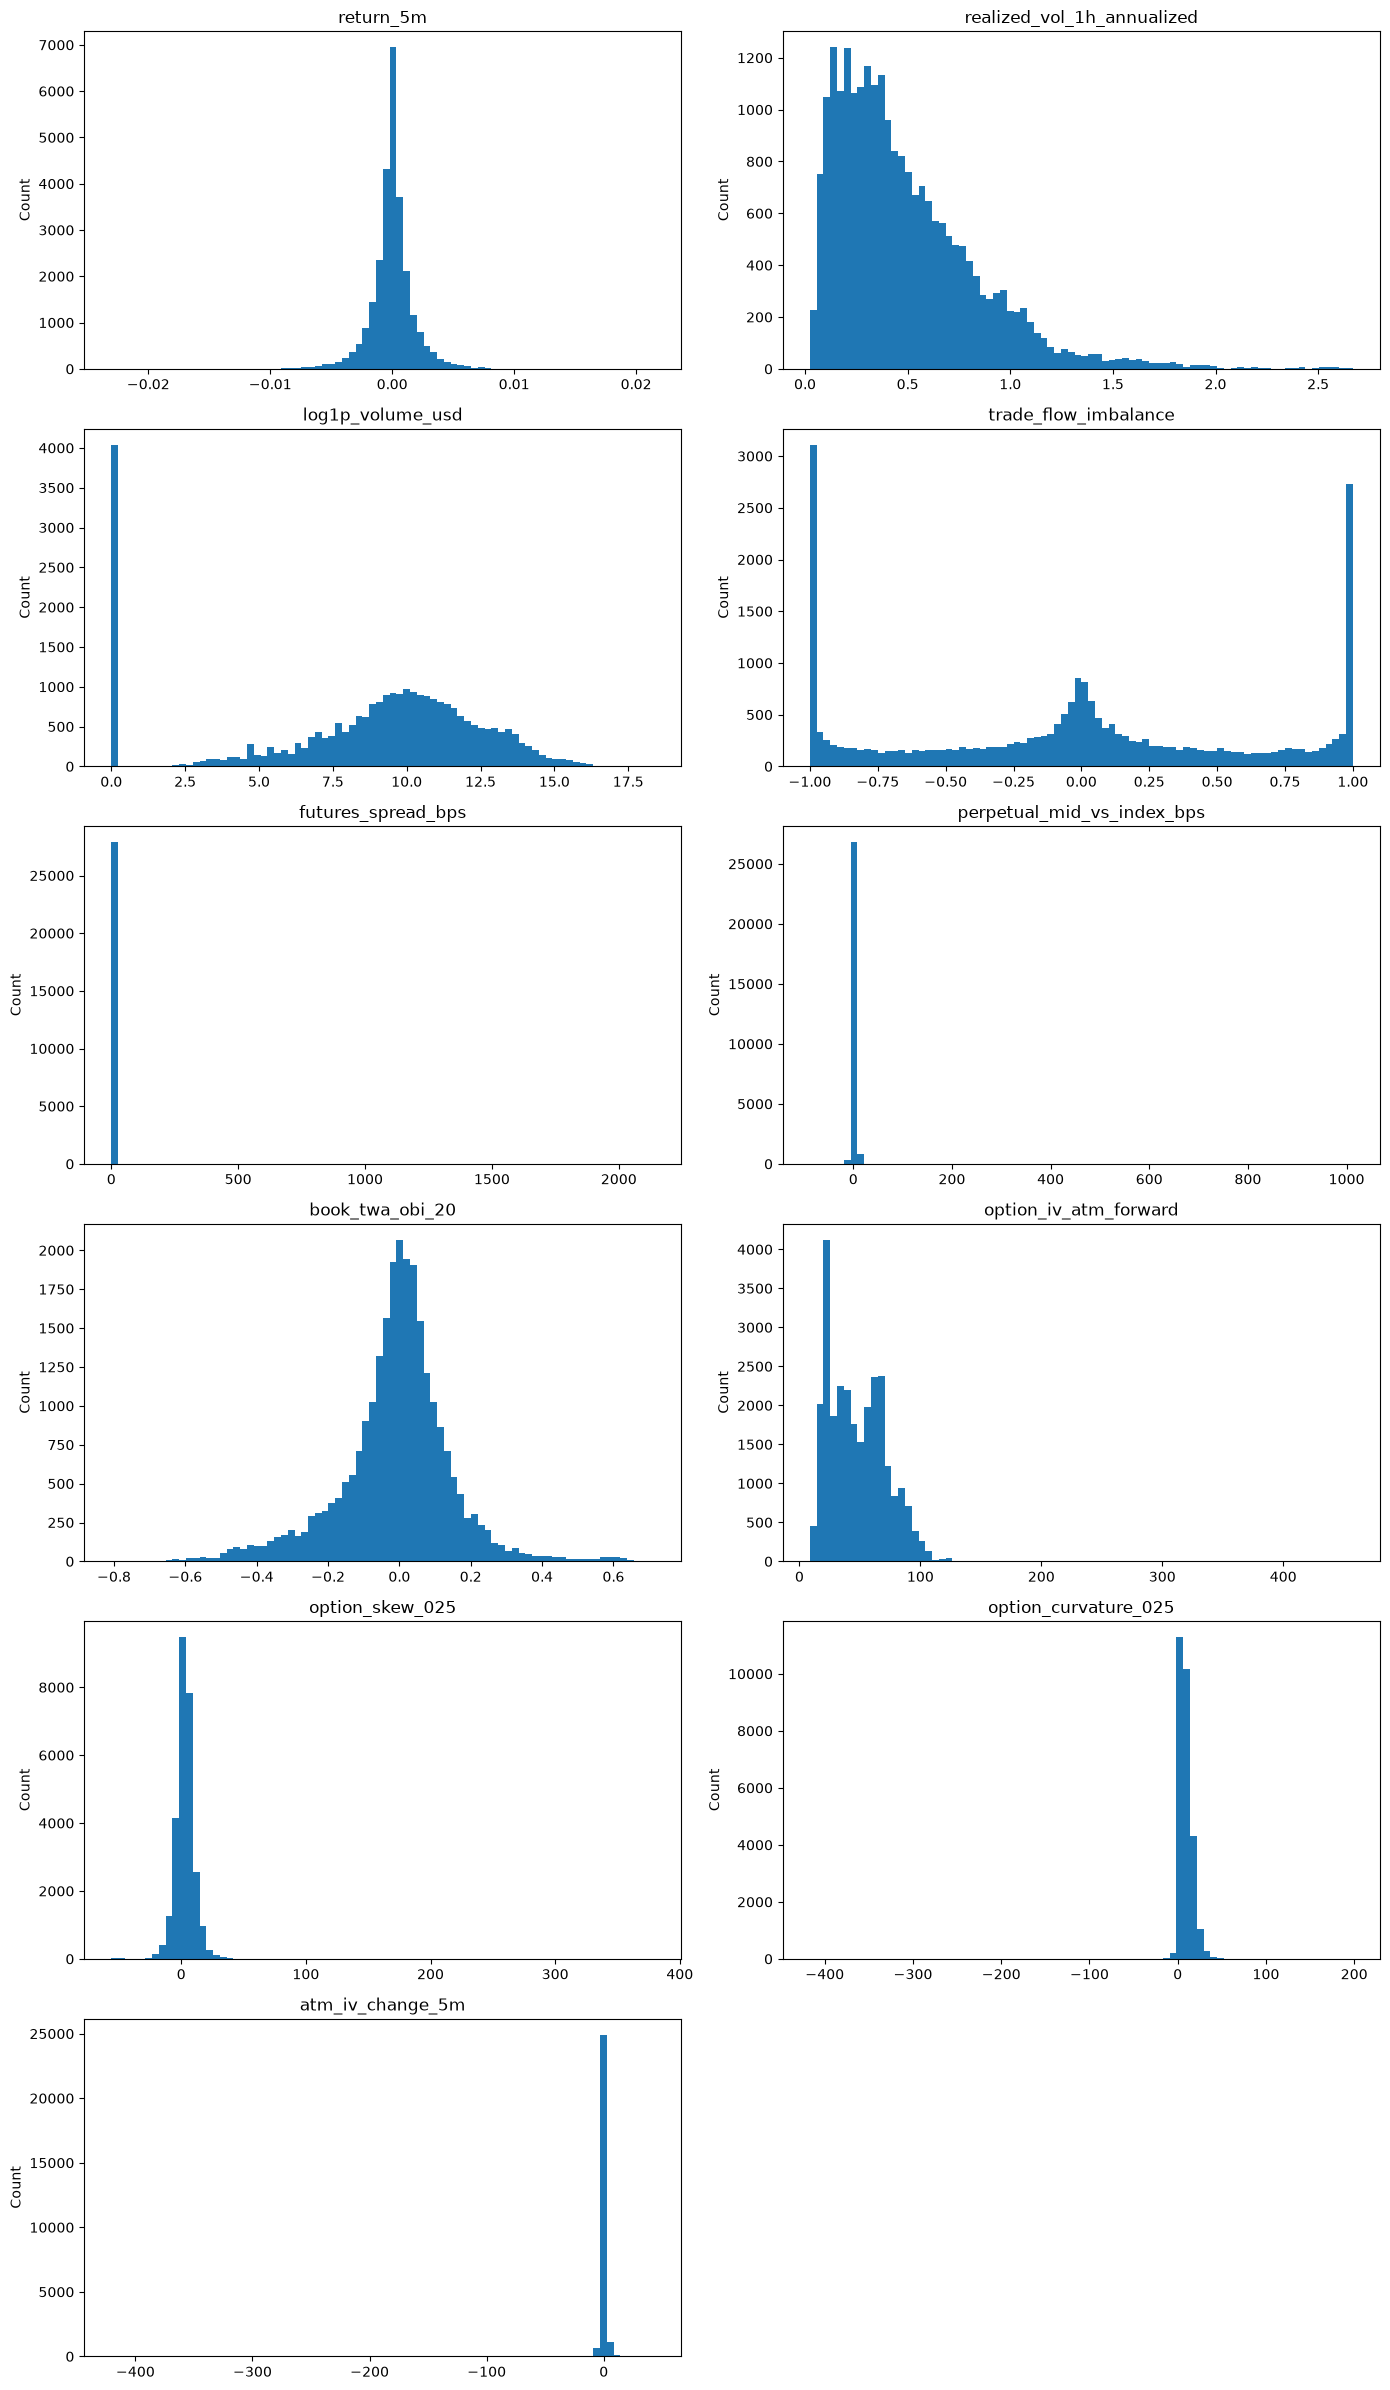

In [20]:
if distribution_features:
    ncols = 2
    nrows = math.ceil(len(distribution_features) / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, col in zip(axes, distribution_features):
        s = pd.to_numeric(features[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if len(s):
            ax.hist(s, bins=80)
            ax.set_title(col)
            ax.set_ylabel("Count")
        else:
            ax.text(0.5, 0.5, "No available observations", ha="center", va="center")
            ax.set_title(col)

    for ax in axes[len(distribution_features):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## 14. Option-family inventory

The final matrix uses one stable primary family, but the long-form table retains all families for robustness research.

In [21]:
if "option_surface_feature_state" in set(relations["table_name"]):
    option_family_inventory = con.execute(
        """
        SELECT
            underlying,
            option_family_id,
            COUNT(*) AS states,
            SUM(CASE WHEN core_smile_usable THEN 1 ELSE 0 END) AS core_usable,
            SUM(CASE WHEN core_surface_change_5m_ready THEN 1 ELSE 0 END) AS dynamic_5m,
            SUM(CASE WHEN delta_25d_smile_available THEN 1 ELSE 0 END) AS delta_25d
        FROM option_surface_feature_state
        GROUP BY underlying, option_family_id
        ORDER BY underlying, option_family_id
        """
    ).df()
    display(option_family_inventory)
else:
    print("option_surface_feature_state is not available.")

,underlying,option_family_id,states,core_usable,dynamic_5m,delta_25d
0,AVAX,AVAX|linear|USDC|USDC,4250,3934.0,3868.0,3534.0
1,BTC,BTC|linear|USDC|USDC,4250,3934.0,3868.0,2455.0
2,BTC,BTC|reversed|BTC|BTC,4250,3934.0,3868.0,2456.0
3,ETH,ETH|linear|USDC|USDC,4250,3934.0,3868.0,2630.0
4,ETH,ETH|reversed|ETH|ETH,4250,3934.0,3868.0,2633.0
5,HYPE,HYPE|linear|USDC|USDC,4250,3934.0,3868.0,3086.0
6,SOL,SOL|linear|USDC|USDC,4250,3934.0,3868.0,3371.0
7,TRX,TRX|linear|USDC|USDC,4250,3934.0,3868.0,1414.0
8,XRP,XRP|linear|USDC|USDC,4250,3815.0,3745.0,3047.0


## 15. L2-instability availability

Historical rows must stay unavailable before the collector upgrade. This verifies first availability by asset without fabricating history.

In [22]:
l2_columns = [c for c in [
    "book_twa_abs_obi_20",
    "book_obi_20_std",
    "book_obi_20_path_roughness_per_min",
    "book_obi_20_range",
    "book_obi_20_coherence_noise",
    "book_obi_20_raw_zero_cross_rate",
    "book_obi_20_reversal_strength_mean",
    "book_obi_20_reversal_strength_max",
] if c in features.columns]

l2_availability = []
for asset, group in features.groupby("underlying"):
    row = {"underlying": asset}
    for col in l2_columns:
        available = group[col].notna()
        row[f"{col}_n"] = int(available.sum())
        row[f"{col}_first"] = group.loc[available, "state_time"].min() if available.any() else pd.NaT
    l2_availability.append(row)

display(pd.DataFrame(l2_availability))

,underlying,book_twa_abs_obi_20_n,book_twa_abs_obi_20_first,book_obi_20_std_n,book_obi_20_std_first,book_obi_20_path_roughness_per_min_n,book_obi_20_path_roughness_per_min_first,book_obi_20_range_n,book_obi_20_range_first,book_obi_20_coherence_noise_n,book_obi_20_coherence_noise_first,book_obi_20_raw_zero_cross_rate_n,book_obi_20_raw_zero_cross_rate_first,book_obi_20_reversal_strength_mean_n,book_obi_20_reversal_strength_mean_first,book_obi_20_reversal_strength_max_n,book_obi_20_reversal_strength_max_first
0,AVAX,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1099,2026-10-01 12:50:00+02:00,1099,2026-10-01 12:50:00+02:00
1,BTC,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1110,2026-10-01 12:50:00+02:00,1110,2026-10-01 12:50:00+02:00
2,ETH,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1107,2026-10-01 12:50:00+02:00,1107,2026-10-01 12:50:00+02:00
3,HYPE,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1116,2026-10-01 12:50:00+02:00,1116,2026-10-01 12:50:00+02:00
4,SOL,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1117,2026-10-01 12:50:00+02:00,1117,2026-10-01 12:50:00+02:00
5,TRX,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,878,2026-10-01 12:55:00+02:00,878,2026-10-01 12:55:00+02:00
6,XRP,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1118,2026-10-01 12:50:00+02:00,1088,2026-10-01 12:50:00+02:00,1088,2026-10-01 12:50:00+02:00


## 16. Coverage through the 0DTE session

We do not impose arbitrary time-to-expiry bins here. This simply shows raw coverage as a function of minutes to expiry.

,minutes_to_expiry,states,research_ready,structural_dynamic
287,1440,112,35,0
286,1435,112,91,35
285,1430,112,91,90
284,1425,112,91,90
283,1420,112,91,90
282,1415,112,91,90
281,1410,112,84,83
280,1405,112,91,83
279,1400,112,84,76
278,1395,112,84,74


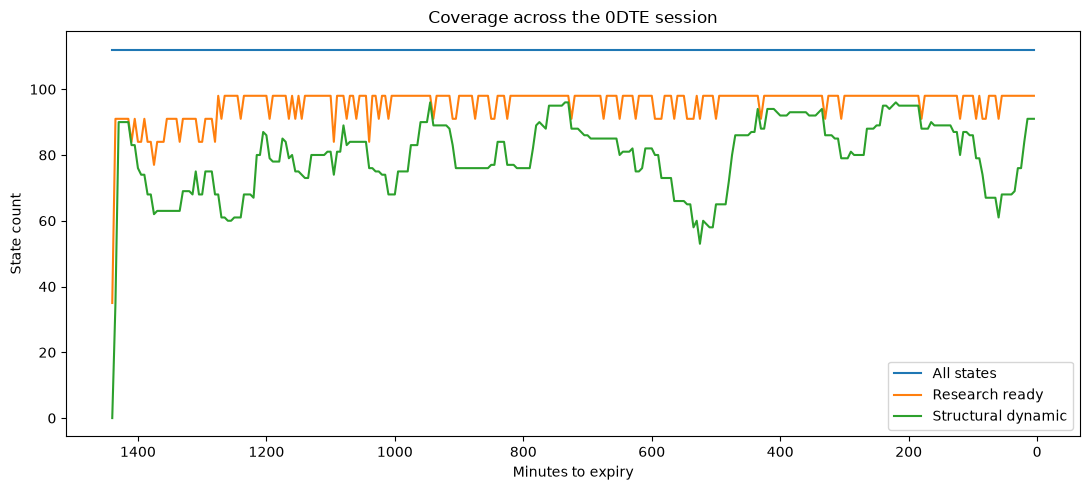

In [23]:
if "minutes_to_expiry" in features.columns:
    session_progress = (
        features.groupby("minutes_to_expiry")
        .agg(
            states=("state_id", "size"),
            research_ready=("state_research_ready", lambda s: int(s.fillna(False).sum())),
            structural_dynamic=("structural_dynamic_features_ready", lambda s: int(s.fillna(False).sum())),
        )
        .reset_index()
        .sort_values("minutes_to_expiry", ascending=False)
    )

    display(session_progress.head(20))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(session_progress["minutes_to_expiry"], session_progress["states"], label="All states")
    ax.plot(session_progress["minutes_to_expiry"], session_progress["research_ready"], label="Research ready")
    ax.plot(session_progress["minutes_to_expiry"], session_progress["structural_dynamic"], label="Structural dynamic")
    ax.invert_xaxis()
    ax.set_xlabel("Minutes to expiry")
    ax.set_ylabel("State count")
    ax.set_title("Coverage across the 0DTE session")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 17. Inventory report objects

In [24]:
inventory_report = {
    "overview": overview,
    "asset_counts": asset_counts,
    "expiry_counts": expiry_counts,
    "dtypes": dtype_inventory,
    "missingness": missingness,
    "readiness": readiness_summary,
    "numeric_summary": numeric_summary,
    "constant_features": constant_summary,
    "irregular_gaps": gap_summary,
    "availability_by_asset": availability_by_asset,
}

print("Inventory report sections:")
for name, frame in inventory_report.items():
    print(f"  {name:<24} {len(frame):>6,} rows")

Inventory report sections:
  overview                      8 rows
  asset_counts                  7 rows
  expiry_counts                16 rows
  dtypes                      152 rows
  missingness                 152 rows
  readiness                    16 rows
  numeric_summary             107 rows
  constant_features             9 rows
  irregular_gaps                0 rows
  availability_by_asset         7 rows


## 18. Interpretation checklist

Before moving to `02_market_distributions.ipynb`, verify:

1. uniqueness checks are zero;
2. expected assets have expected state counts;
3. missingness is explainable by readiness/history rather than unexplained corruption;
4. no candidate numeric features contain infinities;
5. no important features are constant or nearly constant;
6. timestamp gaps are understood;
7. readiness degradation clusters are understood;
8. delta-smile sparsity is materially higher than fixed-moneyness sparsity where expected;
9. L2-instability features begin only after real collection starts;
10. features with unusual tails/scales are identified for dedicated analysis.

No transformation should be promoted into production solely from this notebook.

In [25]:
# Close the read-only connection when finished.
con.close()
print("DuckDB connection closed.")

DuckDB connection closed.
